# Metabolic stress in early-onset preeclampsia placentas: is it robust to the choice of controls?

OpenBio 2026 Datathon, Track 1. This notebook implements `docs/analysis-plan.md`,
which was committed before any test was run. Run all cells top to bottom.

**Question.** Do hypoxia and glycolysis gene-activity signals in early-onset preeclampsia (PE)
placentas persist when cases are compared with preterm controls, and which placental cell
types plausibly carry those signals?

## 0. Setup
Clones the official datathon data package at a pinned commit (so judges get identical files),
downloads MSigDB Hallmark gene sets, and installs PyDESeq2 on Colab.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

DATATHON_REPO = "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git"
DATATHON_COMMIT = "fb751e91fb1eca4fb26a9658ad9d5042c382c4ba"
HALLMARK_URL = ("https://data.broadinstitute.org/gsea-msigdb/msigdb/release/2024.1.Hs/"
                "h.all.v2024.1.Hs.symbols.gmt")

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pydeseq2==0.5.4", "statsmodels"], check=True)
    os.makedirs("/content/team/notebooks", exist_ok=True)
    os.chdir("/content/team/notebooks")

ROOT = Path("..")
datathon_dir = ROOT / "openbio-datathon-2026"
if not datathon_dir.exists():
    subprocess.run(["git", "clone", "-q", DATATHON_REPO, str(datathon_dir)], check=True)
    subprocess.run(["git", "-C", str(datathon_dir), "checkout", "-q", DATATHON_COMMIT], check=True)
DATA_DIR = datathon_dir / "track-01" / "data"

gmt_path = ROOT / "data_external" / "h.all.v2024.1.Hs.symbols.gmt"
if not gmt_path.exists():
    gmt_path.parent.mkdir(exist_ok=True)
    from urllib.request import urlretrieve
    urlretrieve(HALLMARK_URL, gmt_path)

FIG_DIR = ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.decomposition import PCA
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
INFER = DefaultInference(n_cpus=4)
print("Data:", DATA_DIR.resolve())

Data: /Users/bakdauletomertaev/Downloads/PROJECTS/openbio-track1-team/openbio-datathon-2026/track-01/data


## 1. Load and check the data
One villous sample per donor, so each column is one independent pregnancy.

In [2]:
counts = pd.read_csv(DATA_DIR / "track01_counts_vt.csv", index_col=0)
meta = pd.read_csv(DATA_DIR / "track01_metadata_vt.csv", index_col=0).loc[counts.columns]
assert meta["donor_id"].is_unique, "a donor appears twice"
assert (counts.values >= 0).all() and (counts.values % 1 == 0).all()
print(f"{counts.shape[0]:,} genes x {counts.shape[1]} samples; donors unique: {meta.donor_id.is_unique}")
print(meta.groupby("group").ga_delivery_weeks.agg(["count", "min", "median", "max"]).round(1))
print("\nQC flags:\n", meta.loc[meta.qc_flags != "none", ["group", "qc_flags"]])

# Expression filter (mechanics, applied once to all analyses): keep genes with >=10 reads in >=5 samples.
keep = (counts >= 10).sum(axis=1) >= 5
counts_f = counts.loc[keep]
print(f"\nGenes kept after low-count filter: {keep.sum():,}")

GROUP_COLORS = {"EOPE": "#c0392b", "EOPE+FGR": "#8e44ad", "FGR": "#d68910", "iPTB": "#2471a3", "TB": "#17a589"}

26,485 genes x 30 samples; donors unique: True
          count   min  median   max
group                              
EOPE          8  26.0    30.3  33.0
EOPE+FGR      7  26.6    33.0  33.7
FGR           5  26.7    29.0  30.4
TB            5  39.0    39.1  39.4
iPTB          5  29.9    32.0  33.0

QC flags:
               group                                           qc_flags
sample_id                                                             
S04_VT          FGR                            no_pe_with_bp_ge_140_90
S12_VT     EOPE+FGR                            pe_without_bp_ge_140_90
S15_VT          FGR                            no_pe_with_bp_ge_140_90
S26_VT           TB  ga_days_component_gt6;bp_missing;birthweight_m...
S27_VT           TB                     bp_missing;birthweight_missing
S28_VT           TB                     bp_missing;birthweight_missing
S29_VT           TB                     bp_missing;birthweight_missing
S30_VT           TB                     bp_missing

## 2. Explore the samples (PCA)
Variance-stabilised expression, top 2,000 most variable genes. We colour by group and by
gestational age to see whether delivery timing is a major axis.

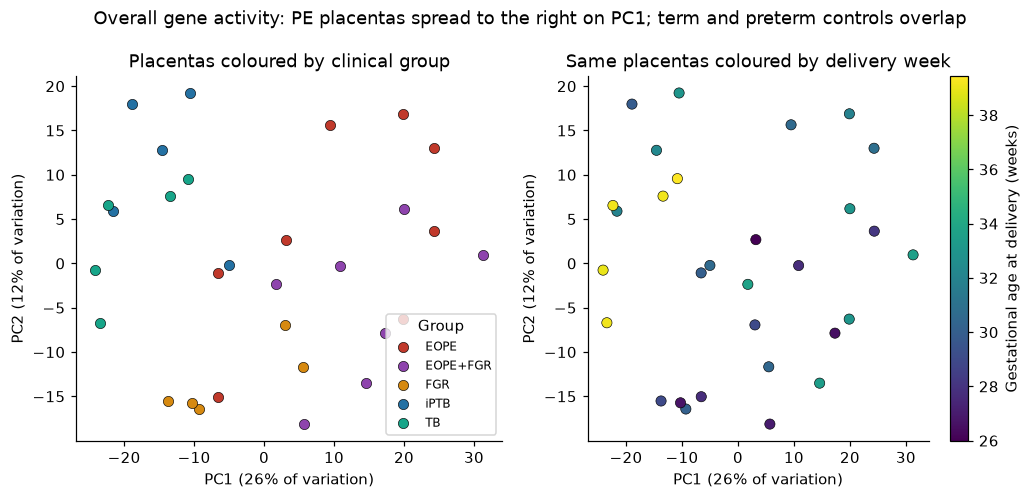

PC1 vs gestational age: Spearman rho = -0.28, p = 0.13
PC2 vs gestational age: Spearman rho = 0.38, p = 0.036
PC1 vs gestational age within preterm samples only: rho = 0.14, p = 0.51
PC1: PE vs all non-PE, Mann-Whitney p = 1.9e-05
PC2: PE vs all non-PE, Mann-Whitney p = 0.84
           PC1   PC2
group               
EOPE      14.7   3.2
EOPE+FGR  14.6  -2.4
FGR       -9.3 -15.5
TB       -22.3   6.5
iPTB     -14.6  12.8


In [3]:
dds_all = DeseqDataSet(counts=counts_f.T.astype(int), metadata=meta[["pe_status"]], design="~pe_status",
                       inference=INFER, quiet=True)
dds_all.fit_size_factors()
dds_all.vst(use_design=False)
vst = pd.DataFrame(dds_all.layers["vst_counts"], index=counts_f.columns, columns=counts_f.index)

top = vst.var().sort_values(ascending=False).index[:2000]
pca = PCA(n_components=4).fit(vst[top] - vst[top].mean())
pcs = pd.DataFrame(pca.transform(vst[top] - vst[top].mean())[:, :4], index=vst.index, columns=["PC1", "PC2", "PC3", "PC4"])
ev = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for g, c in GROUP_COLORS.items():
    m = meta.group == g
    axes[0].scatter(pcs.PC1[m], pcs.PC2[m], c=c, label=g, s=45, edgecolor="k", lw=0.4)
axes[0].legend(title="Group", fontsize=8)
sc = axes[1].scatter(pcs.PC1, pcs.PC2, c=meta.ga_delivery_weeks, cmap="viridis", s=45, edgecolor="k", lw=0.4)
plt.colorbar(sc, ax=axes[1], label="Gestational age at delivery (weeks)")
for ax in axes:
    ax.set_xlabel(f"PC1 ({ev[0]:.0f}% of variation)"); ax.set_ylabel(f"PC2 ({ev[1]:.0f}% of variation)")
axes[0].set_title("Placentas coloured by clinical group"); axes[1].set_title("Same placentas coloured by delivery week")
fig.suptitle("Overall gene activity: PE placentas spread to the right on PC1; term and preterm controls overlap", y=1.02)
plt.savefig(FIG_DIR / "fig1_pca.png", dpi=300, bbox_inches="tight"); plt.show()

for pc in ["PC1", "PC2"]:
    rho, p = stats.spearmanr(pcs[pc], meta.ga_delivery_weeks)
    print(f"{pc} vs gestational age: Spearman rho = {rho:.2f}, p = {p:.2g}")
pre = meta.preterm_delivery == "yes"
rho, p = stats.spearmanr(pcs.PC1[pre], meta.ga_delivery_weeks[pre])
print(f"PC1 vs gestational age within preterm samples only: rho = {rho:.2f}, p = {p:.2g}")
for pc in ["PC1", "PC2"]:
    u = stats.mannwhitneyu(pcs[pc][meta.pe_status == "PE"], pcs[pc][meta.pe_status != "PE"])
    print(f"{pc}: PE vs all non-PE, Mann-Whitney p = {u.pvalue:.2g}")
print(pcs.join(meta.group).groupby("group")[["PC1", "PC2"]].median().round(1))

## 3. Differential expression (primary + predefined sensitivity analyses)
Primary: PE (EOPE + EOPE+FGR, n=15) vs preterm controls (iPTB, n=5), design `~ fetal_sex + pe_status`.
Thresholds fixed in the plan: padj < 0.05, |log2FC| >= 1, baseMean >= 10.

In [4]:
PADJ, LFC, BASEMEAN = 0.05, 1.0, 10

def run_deseq(samples, design, contrast=("pe_status", "PE", "no_PE"), label=""):
    md = meta.loc[samples].copy()
    md["ga_z"] = (md.ga_delivery_weeks - md.ga_delivery_weeks.mean()) / md.ga_delivery_weeks.std()
    c = counts_f[samples].T.astype(int)
    c = c.loc[:, (c >= 10).sum(axis=0) >= min(3, len(samples))]
    dds = DeseqDataSet(counts=c, metadata=md, design=design, inference=INFER, quiet=True)
    dds.deseq2()
    ds = DeseqStats(dds, contrast=list(contrast), inference=INFER, quiet=True)
    ds.summary()
    res = ds.results_df.copy()
    res["hit"] = (res.padj < PADJ) & (res.log2FoldChange.abs() >= LFC) & (res.baseMean >= BASEMEAN)
    print(f"{label:<38} n={len(samples):>2}  hits={int(res.hit.sum()):>4}  "
          f"(up {int((res.hit & (res.log2FoldChange > 0)).sum())}, down {int((res.hit & (res.log2FoldChange < 0)).sum())})")
    return res

PE = meta.index[meta.pe_status == "PE"]
EOPE_only = meta.index[meta.group == "EOPE"]
IPTB = meta.index[meta.group == "iPTB"]
TB = meta.index[meta.group == "TB"]

results = {}
results["primary"] = run_deseq(PE.append(IPTB), "~fetal_sex + pe_status", label="Primary: PE vs iPTB")
results["S1_ga"] = run_deseq(PE.append(IPTB), "~fetal_sex + ga_z + pe_status", label="S1: + gestational-age covariate")
results["S2_eope"] = run_deseq(EOPE_only.append(IPTB), "~fetal_sex + pe_status", label="S2: EOPE without FGR vs iPTB")
results["S3_term"] = run_deseq(PE.append(TB), "~fetal_sex + pe_status", label="S3: PE vs term controls")
for s in IPTB:
    results[f"S4_drop_{s}"] = run_deseq(PE.append(IPTB.drop(s)), "~fetal_sex + pe_status", label=f"S4: drop control {s}")

prim = results["primary"]
prim.sort_values("padj").to_csv(RES_DIR / "deseq_primary_PE_vs_iPTB.csv")
print("\nHits in primary at looser thresholds (transparency only):",
      int(((prim.padj < 0.1) & (prim.log2FoldChange.abs() >= 0.58) & (prim.baseMean >= BASEMEAN)).sum()))

Primary: PE vs iPTB                    n=20  hits= 424  (up 261, down 163)


S1: + gestational-age covariate        n=20  hits= 480  (up 307, down 173)


S2: EOPE without FGR vs iPTB           n=13  hits= 294  (up 205, down 89)


S3: PE vs term controls                n=20  hits= 435  (up 283, down 152)


S4: drop control S05_VT                n=19  hits= 282  (up 196, down 86)


S4: drop control S09_VT                n=19  hits= 358  (up 224, down 134)


S4: drop control S10_VT                n=19  hits= 291  (up 179, down 112)


S4: drop control S23_VT                n=19  hits= 315  (up 208, down 107)


S4: drop control S24_VT                n=19  hits= 515  (up 303, down 212)

Hits in primary at looser thresholds (transparency only): 1264


### Robustness of primary hits
For each sensitivity analysis: what fraction of primary hits keep the same direction and padj < 0.05?

In [5]:
hits = prim.index[prim.hit]
rob = {}
for k, r in results.items():
    if k == "primary":
        continue
    common = hits.intersection(r.index)
    same = (np.sign(r.loc[common, "log2FoldChange"]) == np.sign(prim.loc[common, "log2FoldChange"])) & (r.loc[common, "padj"] < 0.05)
    rob[k] = {"primary_hits": len(hits), "replicated": int(same.sum()), "frac": same.sum() / max(len(hits), 1),
              "own_hits": int(r.hit.sum())}
rob = pd.DataFrame(rob).T
rob.to_csv(RES_DIR / "robustness.csv")
print(rob)

s4 = [k for k in results if k.startswith("S4")]
robust_hits = [g for g in hits if all(g in results[k].index and results[k].loc[g, "padj"] < 0.05 and
               np.sign(results[k].loc[g, "log2FoldChange"]) == np.sign(prim.loc[g, "log2FoldChange"])
               for k in ["S1_ga"] + s4)]
print(f"\nPrimary hits robust to GA covariate AND every leave-one-control-out: {len(robust_hits)}")
prim.loc[robust_hits].sort_values("padj").to_csv(RES_DIR / "robust_hits.csv")

                primary_hits  replicated      frac  own_hits
S1_ga                  424.0       397.0  0.936321     480.0
S2_eope                424.0       250.0  0.589623     294.0
S3_term                424.0       233.0  0.549528     435.0
S4_drop_S05_VT         424.0       291.0  0.686321     282.0
S4_drop_S09_VT         424.0       328.0  0.773585     358.0
S4_drop_S10_VT         424.0       266.0  0.627358     291.0
S4_drop_S23_VT         424.0       280.0  0.660377     315.0
S4_drop_S24_VT         424.0       379.0  0.893868     515.0

Primary hits robust to GA covariate AND every leave-one-control-out: 207


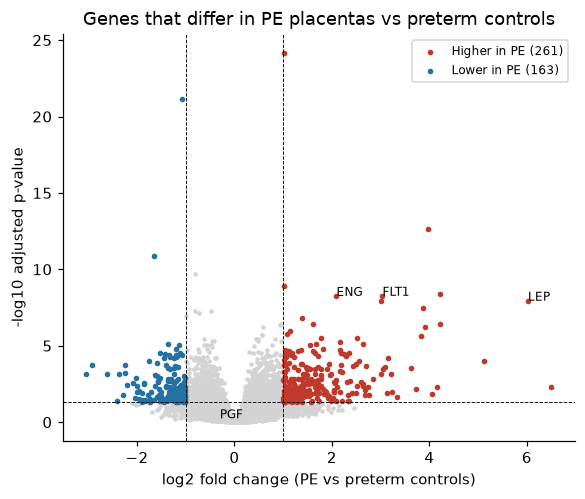

Anchor genes (sanity check, known PE biology):
           baseMean  log2FoldChange    padj
gene                                       
FLT1    126520.1845          3.0384  0.0000
ENG       7529.8893          2.0939  0.0000
LEP      24964.6564          6.0238  0.0000
PGF       7438.2237         -0.2978  0.5597
INHA      1433.6064          1.9920  0.0007
PAPPA2  142898.3158          1.8278  0.0000


In [6]:
fig, ax = plt.subplots(figsize=(6, 4.8))
r = prim.dropna(subset=["padj"])
y = -np.log10(r.padj.clip(lower=1e-30))
ax.scatter(r.log2FoldChange, y, s=4, c="lightgrey")
up = r.hit & (r.log2FoldChange > 0); dn = r.hit & (r.log2FoldChange < 0)
ax.scatter(r.log2FoldChange[up], y[up], s=7, c="#c0392b", label=f"Higher in PE ({up.sum()})")
ax.scatter(r.log2FoldChange[dn], y[dn], s=7, c="#2471a3", label=f"Lower in PE ({dn.sum()})")
for g in ["FLT1", "ENG", "LEP", "PGF"]:
    if g in r.index:
        ax.annotate(g, (r.loc[g, "log2FoldChange"], -np.log10(max(r.loc[g, "padj"], 1e-30))), fontsize=8)
ax.axhline(-np.log10(PADJ), ls="--", c="k", lw=0.6); [ax.axvline(v, ls="--", c="k", lw=0.6) for v in (-LFC, LFC)]
ax.set_xlabel("log2 fold change (PE vs preterm controls)"); ax.set_ylabel("-log10 adjusted p-value")
ax.set_title("Genes that differ in PE placentas vs preterm controls"); ax.legend(fontsize=8)
plt.savefig(FIG_DIR / "fig2_volcano.png", dpi=300, bbox_inches="tight"); plt.show()

print("Anchor genes (sanity check, known PE biology):")
print(prim.loc[[g for g in ["FLT1", "ENG", "LEP", "PGF", "INHA", "PAPPA2"] if g in prim.index],
               ["baseMean", "log2FoldChange", "padj"]].round(4))

## 4. Predefined pathways: hypoxia and glycolysis, donor by donor
Score = mean z-score (across all 30 samples) of variance-stabilised expression of set genes.

In [7]:
gmt = {line.split("\t")[0]: line.rstrip("\n").split("\t")[2:] for line in open(gmt_path)}
SETS = ["HALLMARK_HYPOXIA", "HALLMARK_GLYCOLYSIS"]
z = (vst - vst.mean()) / vst.std()
scores = pd.DataFrame({s: z[[g for g in gmt[s] if g in z.columns]].mean(axis=1) for s in SETS})
for s in SETS:
    print(f"{s}: {sum(g in z.columns for g in gmt[s])}/{len(gmt[s])} genes present")
scores = scores.join(meta[["group", "pe_status", "ga_delivery_weeks", "fetal_sex"]])
scores.to_csv(RES_DIR / "pathway_scores.csv")

rows = []
for s in SETS:
    sub = scores.loc[PE.append(IPTB)].copy(); sub["PE"] = (sub.pe_status == "PE").astype(int)
    u = stats.mannwhitneyu(sub.loc[sub.PE == 1, s], sub.loc[sub.PE == 0, s], alternative="two-sided")
    ols = smf.ols(f"{s} ~ PE + ga_delivery_weeks + C(fetal_sex)", data=sub).fit()
    sub_t = scores.loc[PE.append(TB)].copy(); sub_t["PE"] = (sub_t.pe_status == "PE").astype(int)
    u_t = stats.mannwhitneyu(sub_t.loc[sub_t.PE == 1, s], sub_t.loc[sub_t.PE == 0, s], alternative="two-sided")
    # competitive test on the DESeq2 Wald statistic (anti-conservative; genes are correlated)
    st = prim["stat"].dropna(); inset = st.index.isin(gmt[s])
    w = stats.mannwhitneyu(st[inset], st[~inset], alternative="two-sided")
    rows.append({"set": s,
                 "median_PE": sub.loc[sub.PE == 1, s].median(), "median_iPTB": sub.loc[sub.PE == 0, s].median(),
                 "MWU_p_PE_vs_iPTB": u.pvalue,
                 "OLS_PE_coef": ols.params["PE"], "OLS_PE_CI": tuple(ols.conf_int().loc["PE"].round(3)), "OLS_PE_p": ols.pvalues["PE"],
                 "MWU_p_PE_vs_TB": u_t.pvalue, "competitive_p": w.pvalue,
                 "PE_above_max_iPTB": int((sub.loc[sub.PE == 1, s] > sub.loc[sub.PE == 0, s].max()).sum())})
path_stats = pd.DataFrame(rows).set_index("set")
path_stats.to_csv(RES_DIR / "pathway_stats.csv")
print(path_stats.T)

HALLMARK_HYPOXIA: 177/200 genes present
HALLMARK_GLYCOLYSIS: 177/200 genes present
set               HALLMARK_HYPOXIA HALLMARK_GLYCOLYSIS
median_PE                 0.074593            0.202274
median_iPTB              -0.113534           -0.116194
MWU_p_PE_vs_iPTB          0.010707            0.041796
OLS_PE_coef               0.450452            0.297815
OLS_PE_CI           (0.154, 0.747)      (0.087, 0.508)
OLS_PE_p                  0.005384            0.008535
MWU_p_PE_vs_TB            0.000129            0.005418
competitive_p                  0.0                 0.0
PE_above_max_iPTB               11                  11


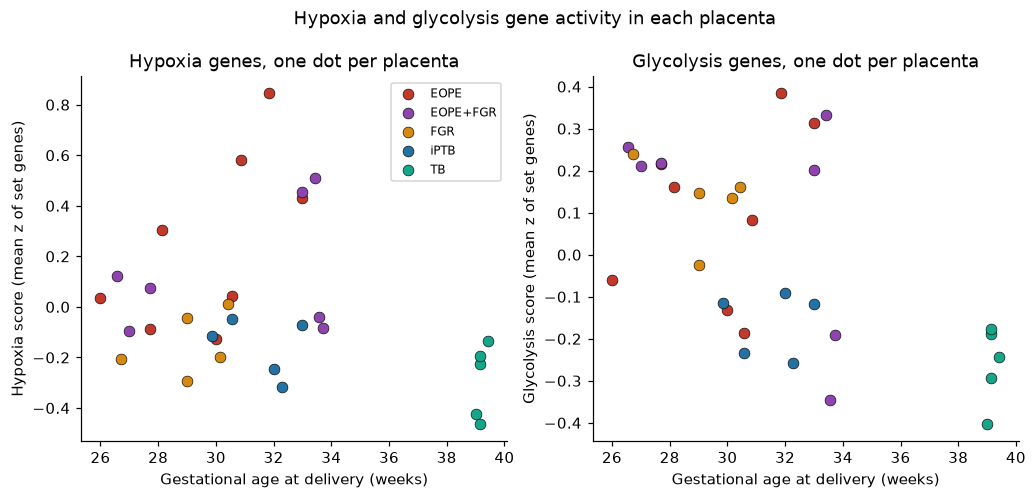

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=False)
for ax, s in zip(axes, SETS):
    for g, c in GROUP_COLORS.items():
        m = scores.group == g
        ax.scatter(scores.ga_delivery_weeks[m], scores[s][m], c=c, label=g, s=50, edgecolor="k", lw=0.4)
    ax.set_xlabel("Gestational age at delivery (weeks)")
    ax.set_ylabel(f"{s.split('_')[1].title()} score (mean z of set genes)")
    ax.set_title(s.replace("HALLMARK_", "").title() + " genes, one dot per placenta")
axes[0].legend(fontsize=8)
fig.suptitle("Hypoxia and glycolysis gene activity in each placenta", y=1.02)
plt.savefig(FIG_DIR / "fig3_pathway_scores.png", dpi=300, bbox_inches="tight"); plt.show()

### 4b. *Post hoc* check (added after seeing Figure 3): is the signal specific to PE?
Figure 3 suggested that FGR-only placentas (no PE) also have high glycolysis scores, and that
glycolysis falls with delivery week. This check was **not** in the pre-registered plan.

In [9]:
FGR_only = meta.index[meta.group == "FGR"]
for s in SETS:
    a, b = scores.loc[FGR_only, s], scores.loc[IPTB, s]
    print(f"{s}: FGR-only median {a.median():.2f} vs iPTB {b.median():.2f}, MWU p = {stats.mannwhitneyu(a, b).pvalue:.3f}")
    pre_s = scores[meta.preterm_delivery == "yes"]
    r, p = stats.spearmanr(pre_s.ga_delivery_weeks, pre_s[s])
    print(f"   within all preterm placentas: score vs gestational age rho = {r:.2f}, p = {p:.3f}")
    pe_s = scores.loc[PE]
    print(f"   within PE: FGR {pe_s[pe_s.index.isin(meta.index[meta.fgr_status=='FGR'])][s].median():.2f} "
          f"vs no FGR {pe_s[~pe_s.index.isin(meta.index[meta.fgr_status=='FGR'])][s].median():.2f}")
print("Overlap between the two gene sets:", len(set(gmt[SETS[0]]) & set(gmt[SETS[1]])), "genes")

HALLMARK_HYPOXIA: FGR-only median -0.20 vs iPTB -0.11, MWU p = 0.690
   within all preterm placentas: score vs gestational age rho = 0.18, p = 0.394
   within PE: FGR 0.07 vs no FGR 0.17
HALLMARK_GLYCOLYSIS: FGR-only median 0.15 vs iPTB -0.12, MWU p = 0.008
   within all preterm placentas: score vs gestational age rho = -0.31, p = 0.136
   within PE: FGR 0.21 vs no FGR 0.12
Overlap between the two gene sets: 65 genes


## 5. Cell-type context: marker table (cell mix vs cell behaviour)
If most markers of one class move together in PE, a change in cell proportions is a strong
alternative explanation; if markers are flat but genes used by that class change, a change in
behaviour is more likely.

                          n_markers  n_measured  mean_lfc  n_up  n_down  \
cell_class                                                                
decidual_stromal_cell             4           4     -0.34     1       3   
decidual_macrophage               4           4     -0.12     2       2   
extravillous_trophoblast          4           4     -0.10     2       2   
villous_cytotrophoblast           4           4     -0.06     1       3   
perivascular_cell                 4           4      0.13     3       1   
endothelial_cell                  4           4      0.33     3       1   
decidual_nk_cell                  4           4      0.44     3       1   
syncytiotrophoblast               4           4      0.45     3       1   
t_cell                            4           0       NaN     0       0   

                          n_padj05  
cell_class                          
decidual_stromal_cell            0  
decidual_macrophage              1  
extravillous_trophoblast  

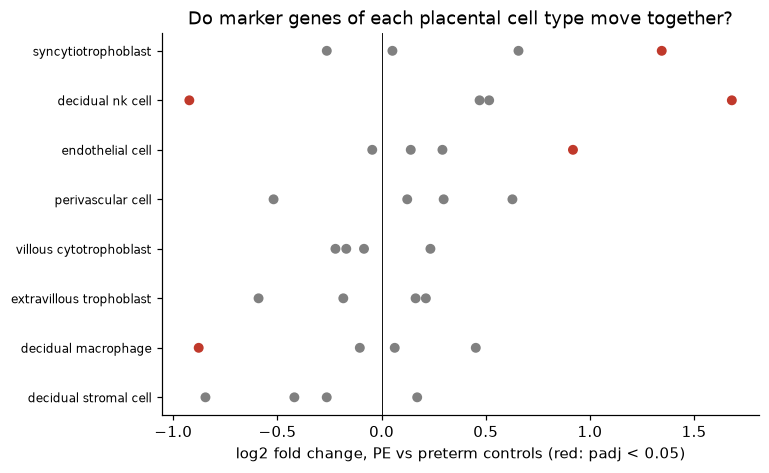

In [10]:
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")
mk = markers.merge(prim[["baseMean", "log2FoldChange", "padj"]], left_on="gene_symbol", right_index=True, how="left")
mk.to_csv(RES_DIR / "marker_results.csv", index=False)
summary = mk.groupby("cell_class").agg(n_markers=("gene_symbol", "size"), n_measured=("log2FoldChange", "count"),
                                       mean_lfc=("log2FoldChange", "mean"),
                                       n_up=("log2FoldChange", lambda x: int((x > 0).sum())),
                                       n_down=("log2FoldChange", lambda x: int((x < 0).sum())),
                                       n_padj05=("padj", lambda x: int((x < 0.05).sum()))).sort_values("mean_lfc")
print(summary.round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
order = summary.index[summary.n_measured > 0]
print("Classes with no marker passing the expression filter:", list(summary.index[summary.n_measured == 0]))
for i, cls in enumerate(order):
    sub = mk[(mk.cell_class == cls)].dropna(subset=["log2FoldChange"])
    ax.scatter(sub.log2FoldChange, [i] * len(sub), c=np.where(sub.padj < 0.05, "#c0392b", "grey"), s=30)
ax.set_yticks(range(len(order))); ax.set_yticklabels([c.replace("_", " ") for c in order], fontsize=8)
ax.axvline(0, c="k", lw=0.6)
ax.set_xlabel("log2 fold change, PE vs preterm controls (red: padj < 0.05)")
ax.set_title("Do marker genes of each placental cell type move together?")
plt.savefig(FIG_DIR / "fig4_markers.png", dpi=300, bbox_inches="tight"); plt.show()

## 6. Candidates for the gene-browser lookup
Robust hits (survive GA covariate and every leave-one-control-out) with baseMean >= 100, plus their
hypoxia/glycolysis membership. Browser observations are recorded in `results/browser_lookups.csv`.

In [11]:
cand = prim.loc[robust_hits].query("baseMean >= 100").copy()
for s in SETS:
    cand[s.replace("HALLMARK_", "")] = cand.index.isin(gmt[s])
cand["marker_class"] = cand.index.map(markers.groupby("gene_symbol").cell_class.first())
cand = cand.sort_values("padj")
cand.to_csv(RES_DIR / "browser_candidates.csv")
print(cand[["baseMean", "log2FoldChange", "padj", "HYPOXIA", "GLYCOLYSIS", "marker_class"]].head(30).round(4))
print("\nRobust hits in hypoxia set:", sorted(cand.index[cand.HYPOXIA]))
print("Robust hits in glycolysis set:", sorted(cand.index[cand.GLYCOLYSIS]))

              baseMean  log2FoldChange  padj  HYPOXIA  GLYCOLYSIS  \
gene                                                                
LEPROTL1      741.1668          1.0181   0.0    False       False   
COASY         820.2251         -1.0741   0.0    False       False   
NTRK2         256.3843          3.9705   0.0    False       False   
AFF3          260.8830         -1.6482   0.0    False       False   
AMD1         3677.1160          1.0260   0.0    False       False   
CP            162.5385          4.2258   0.0     True       False   
FLT1       126520.1845          3.0384   0.0    False       False   
ENG          7529.8893          2.0939   0.0    False       False   
LEP         24964.6564          6.0238   0.0    False       False   
HTRA4        9870.0581          2.9983   0.0    False       False   
UCA1          537.5881          3.8647   0.0    False       False   
HEXB        10462.1307          1.3924   0.0    False       False   
ARMS2         395.7075          4.